In [16]:
pip install mne-connectivity

     -------------------------------------- 115.2/115.2 KB 3.4 MB/s eta 0:00:00
     ---------------------------------------- 7.0/7.0 MB 12.8 MB/s eta 0:00:00
     ------------------------------------- 189.2/189.2 KB 11.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\windows\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [1]:
import mne

# 파일 경로 지정
file_path = "D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/sub-01_ses-01_eeg-epo.fif"

In [2]:
# epochs 객체 불러오기
epochs = mne.read_epochs(file_path, preload=True)

Reading D:\Users\windows\Desktop\Inner Speech Decoding\Dataset\sub-01_ses-01_eeg-epo.fif ...
    Found the data of interest:
        t =    -500.00 ...    4000.00 ms
        0 CTF compensation matrices available
Not setting metadata
54 matching events found
No baseline correction applied
0 projection items activated


In [3]:
epochs

<EpochsFIF | 54 events (all good), -0.5 – 4 s (baseline off), ~61.5 MB, data loaded,
 'arriba': 12
 'abajo': 14
 'derecha': 11
 'izquierda': 17>

In [4]:
print(epochs.get_data().shape)  # (n_epochs, n_channels, n_times)

(54, 129, 1153)


In [25]:
from mne_connectivity import spectral_connectivity_epochs

sfreq = epochs.info['sfreq']

conn = spectral_connectivity_epochs(
    epochs, method='coh', sfreq=sfreq, fmin=8, fmax=13, faverage=True
)

con_matrix = conn.get_data(output='dense')  # 연결성 행렬 (channels x channels x freqs)
freqs = conn.freqs                           # 주파수 배열
n_epochs = conn.n_epochs                     # 에포크 개수

# n_tapers 속성 존재 여부 확인 후 접근
n_tapers = getattr(conn, 'n_tapers', None)

print(con_matrix.shape)
print(freqs)
print(n_epochs, n_tapers)


Connectivity computation...
only using indices for lower-triangular matrix
    computing connectivity for 8256 connections
    using t=-0.500s..4.000s for estimation (1153 points)
    frequencies: 8.2Hz..12.9Hz (22 points)
    connectivity scores will be averaged for each band
    Using multitaper spectrum estimation with 7 DPSS windows
    the following metrics will be computed: Coherence
    computing cross-spectral density for epoch 1


C:\Users\windows\AppData\Local\Temp\ipykernel_16332\3140285222.py:5: RuntimeWarning: There were no Annotations stored in <EpochsFIF | 54 events (all good), -0.5 – 4 s (baseline off), ~61.5 MB, data loaded,
 'arriba': 12
 'abajo': 14
 'derecha': 11
 'izquierda': 17>, so metadata was not modified.
  conn = spectral_connectivity_epochs(


    computing cross-spectral density for epoch 2
    computing cross-spectral density for epoch 3
    computing cross-spectral density for epoch 4
    computing cross-spectral density for epoch 5
    computing cross-spectral density for epoch 6
    computing cross-spectral density for epoch 7
    computing cross-spectral density for epoch 8
    computing cross-spectral density for epoch 9
    computing cross-spectral density for epoch 10
    computing cross-spectral density for epoch 11
    computing cross-spectral density for epoch 12
    computing cross-spectral density for epoch 13
    computing cross-spectral density for epoch 14
    computing cross-spectral density for epoch 15
    computing cross-spectral density for epoch 16
    computing cross-spectral density for epoch 17
    computing cross-spectral density for epoch 18
    computing cross-spectral density for epoch 19
    computing cross-spectral density for epoch 20
    computing cross-spectral density for epoch 21
    comp

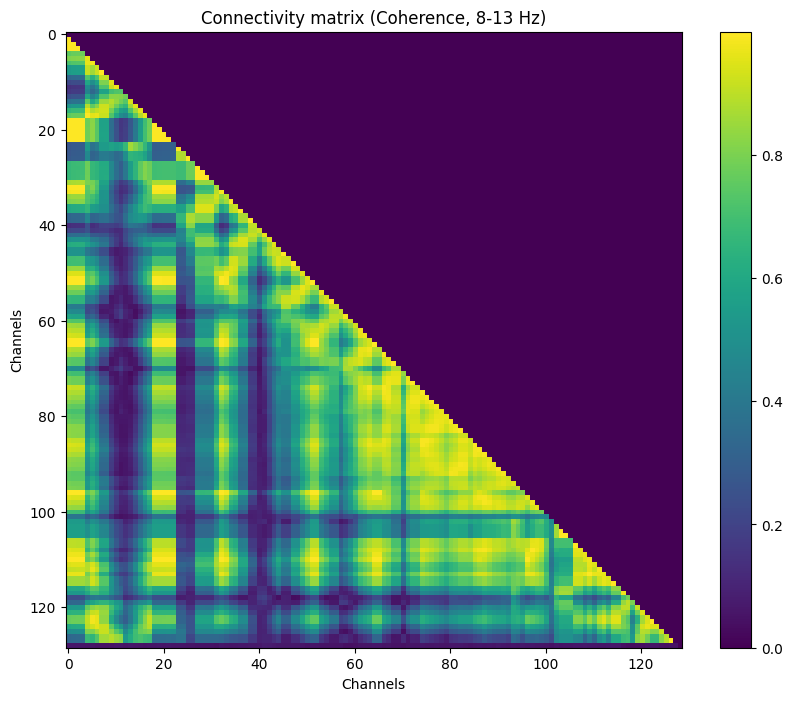

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# con_matrix는 (채널 x 채널 x 주파수) 모양, 마지막 차원이 1이니까 슬라이스
conn_mat_2d = con_matrix[:, :, 0]

plt.figure(figsize=(10, 8))
im = plt.imshow(conn_mat_2d, cmap='viridis', interpolation='nearest')
plt.colorbar(im)
plt.title('Connectivity matrix (Coherence, 8-13 Hz)')
plt.xlabel('Channels')
plt.ylabel('Channels')
plt.show()


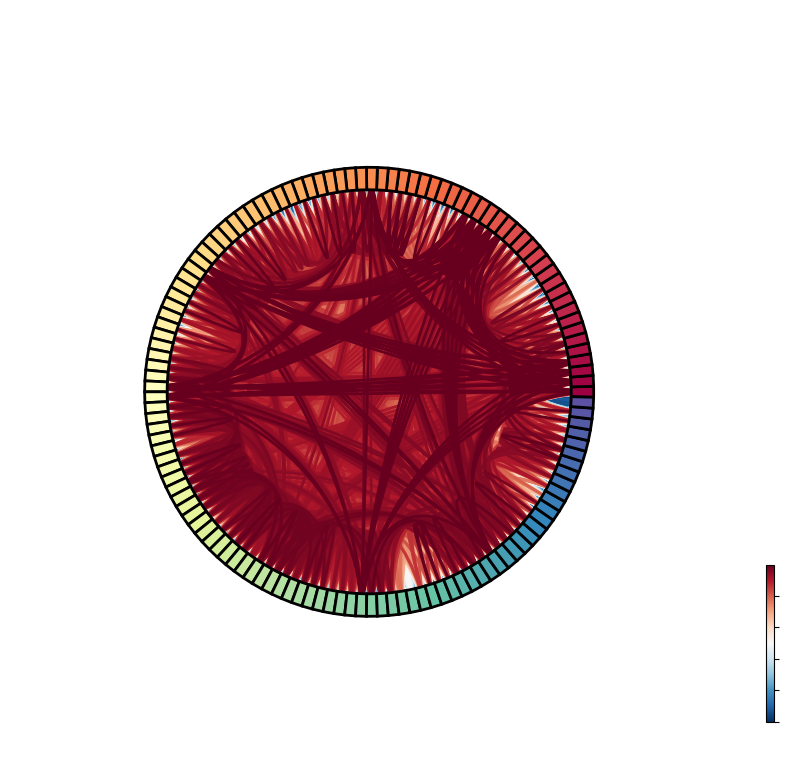

(<Figure size 800x800 with 2 Axes>,
 <PolarAxes: title={'center': 'Connectivity Circle Plot (8-13 Hz)'}>)

In [33]:
from mne_connectivity.viz import plot_connectivity_circle
import matplotlib.pyplot as plt

conn_mat_2d = con_matrix[:, :, 0]
ch_names = epochs.ch_names

plot_connectivity_circle(
    conn_mat_2d, ch_names,
    show=True,
    title='Connectivity Circle Plot (8-13 Hz)',
    vmin=0,
    vmax=conn_mat_2d.max(),
    colormap='RdBu_r',   # 빨강-파랑 스펙트럼
    facecolor='white',
    colorbar=True,
    fontsize_title=14,
    fontsize_names=8,
    linewidth=2
)


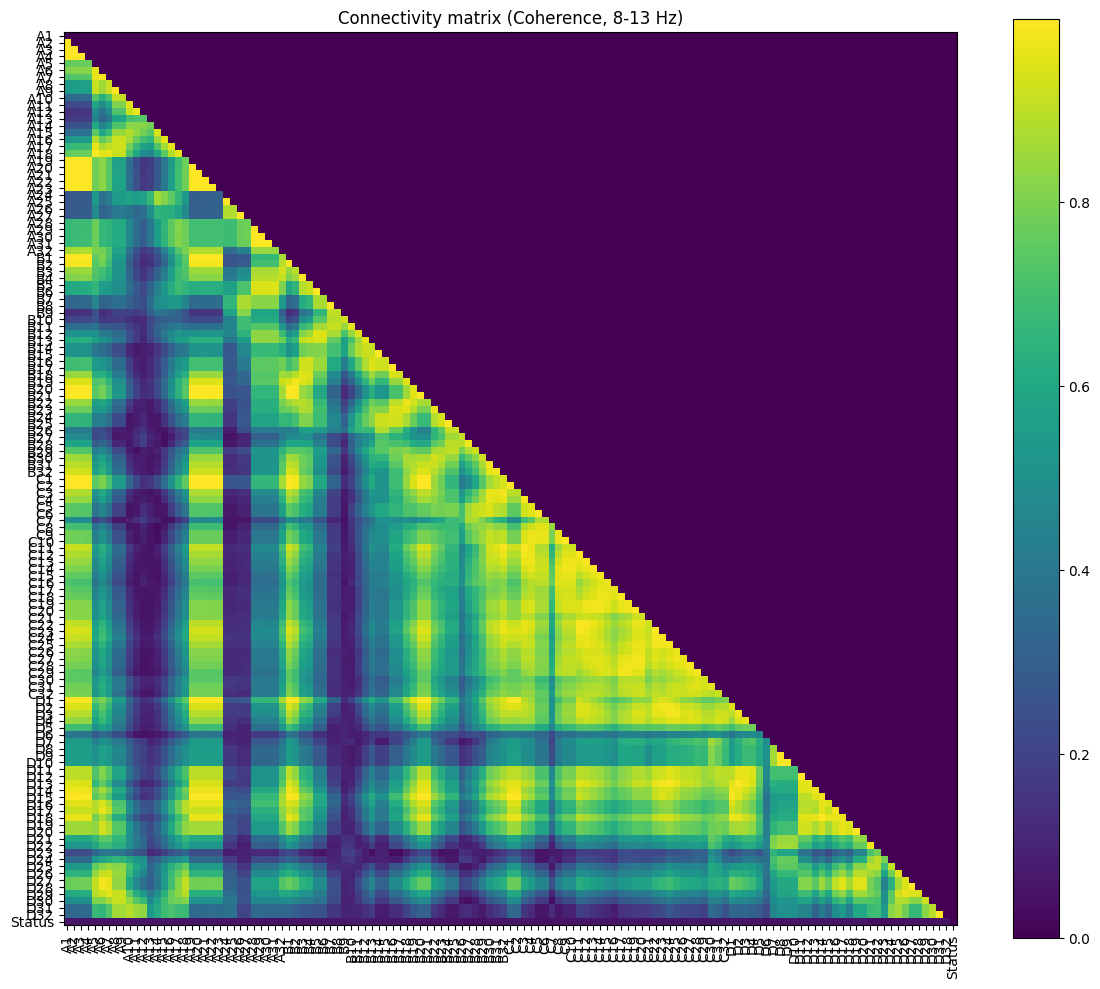

In [27]:
plt.figure(figsize=(12, 10))
im = plt.imshow(conn_mat_2d, cmap='viridis', interpolation='nearest')
plt.colorbar(im)
plt.title('Connectivity matrix (Coherence, 8-13 Hz)')
plt.xticks(ticks=np.arange(len(epochs.ch_names)), labels=epochs.ch_names, rotation=90)
plt.yticks(ticks=np.arange(len(epochs.ch_names)), labels=epochs.ch_names)
plt.tight_layout()
plt.show()